In [3]:
# =========================================================
# Section 0: Imports and global plotting style
# Loads all libraries used throughout the analysis and
# applies a consistent look to every figure.
# =========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

mpl.rcParams.update({
    'figure.dpi': 120, 'font.size': 11, 'axes.titlesize': 12,
    'axes.labelsize': 11, 'legend.fontsize': 10,
    'axes.grid': True, 'grid.alpha': 0.3,
})

In [4]:
# =========================================================
# Section 1: Load and clean the dataset
# - Reads the FuelWatch-derived CSV
# - Sets the date column as the index
# - Drops the first ~30 rows that contain NaN from lag/rolling features
# - Creates day-of-week dummies (Monday is the baseline, so we keep 6)
# Corresponds to proposal §4.1 (Data Collection and Preparation).
# =========================================================
df = pd.read_csv('modelling_dataset.csv', parse_dates=['date'])
df = df.sort_values('date').set_index('date')
df = df.dropna()
df = pd.get_dummies(df, columns=['day_of_week'],
                    prefix='dow', drop_first=True, dtype=int)

print(f"Clean dataset: {df.shape[0]} rows, {df.shape[1]} columns")
print(df.head())

Clean dataset: 3622 rows, 30 columns
             avg_price  median_price  min_price  max_price  num_stations  \
date                                                                       
2016-07-31  112.079872         113.9       99.8      125.9           313   
2016-08-01  109.745048         111.9       97.8      125.9           313   
2016-08-02  122.786262         124.9       97.7      129.9           313   
2016-08-03  119.764856         121.9       96.8      125.9           313   
2016-08-04  117.103195         119.9       96.3      125.9           313   

            target_next_day       lag_1       lag_2       lag_3       lag_7  \
date                                                                          
2016-07-31       109.745048  113.871246  115.792652  119.152396  114.257188   
2016-08-01       122.786262  112.079872  113.871246  115.792652  112.190415   
2016-08-02       119.764856  109.745048  112.079872  113.871246  124.327157   
2016-08-03       117.103195  122.78

In [5]:
# =========================================================
# Section 2: Define the final feature set
# The 6 core predictors were retained after pruning redundant
# and collinear columns (see the multicollinearity diagnosis).
# Day-of-week dummies capture the weekly cycle.
# Corresponds to proposal §4.1 (Feature Engineering).
# =========================================================
base_features = [
    'avg_price',          # today's price level
    'rolling_std_7',      # short-term volatility
    'price_change_1d',    # daily momentum
    'price_change_7d',    # weekly momentum
    'brent_price_usd',    # external: oil benchmark
    'aud_per_usd',        # external: exchange rate
]
dow_features = [c for c in df.columns if c.startswith('dow_')]
feature_cols = base_features + dow_features

print("Features:", feature_cols)
print("Count:", len(feature_cols))

Features: ['avg_price', 'rolling_std_7', 'price_change_1d', 'price_change_7d', 'brent_price_usd', 'aud_per_usd', 'dow_1', 'dow_2', 'dow_3', 'dow_4', 'dow_5', 'dow_6']
Count: 12


In [6]:
# =========================================================
# Section 3: Chronological train/validation/test split
# No shuffling is used because the data is a time series.
# 70% train, 15% validation, 15% test.
# The validation set is used for tuning; the test set is
# kept hidden until final evaluation.
# Corresponds to proposal §4.3 (Validation and Evaluation).
# =========================================================
n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

train = df.iloc[:train_end]
val   = df.iloc[train_end:val_end]
test  = df.iloc[val_end:]

X_train = train[feature_cols].astype(float); y_train = train['target_next_day']
X_val   = val[feature_cols].astype(float);   y_val   = val['target_next_day']
X_test  = test[feature_cols].astype(float);  y_test  = test['target_next_day']

print(f"Train: {len(train)} | Val: {len(val)} | Test: {len(test)}")

Train: 2535 | Val: 543 | Test: 544


In [7]:
# =========================================================
# Section 4: Fit the multiple linear regression model
# Uses statsmodels OLS with a constant added.
# Prints the full regression summary including coefficients,
# standard errors, p-values, R², F-statistic, and diagnostics.
# Corresponds to proposal §4.2 (Modelling Approach - Regression tier).
# =========================================================
X_train_const = sm.add_constant(X_train)
model = sm.OLS(y_train, X_train_const).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        target_next_day   R-squared:                       0.938
Model:                            OLS   Adj. R-squared:                  0.937
Method:                 Least Squares   F-statistic:                     3166.
Date:                Tue, 06 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:46:01   Log-Likelihood:                -8172.0
No. Observations:                2535   AIC:                         1.637e+04
Df Residuals:                    2522   BIC:                         1.645e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              42.2077      3.298     

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data['feature'] = X_train.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

print("\nVariance Inflation Factors (final 12-predictor model):")
print(vif_data.sort_values('VIF', ascending=False).to_string(index=False))


Variance Inflation Factors (final 12-predictor model):
        feature        VIF
      avg_price 152.581377
brent_price_usd  59.819436
    aud_per_usd  45.102559
  rolling_std_7  12.557698
          dow_2   2.738508
          dow_1   2.402187
          dow_3   2.308593
          dow_4   2.177932
          dow_5   2.073328
          dow_6   2.021779
price_change_1d   1.812607
price_change_7d   1.209446


In [9]:
# =========================================================
# Section 5: Generate predictions
# Produces next-day price predictions on the validation and
# test sets. Also stores the naive persistence prediction
# (tomorrow = today) as the baseline comparison.
# =========================================================
y_pred_val  = model.predict(sm.add_constant(X_val))
y_pred_test = model.predict(sm.add_constant(X_test))
y_pred_naive_test = X_test['avg_price'].values

print("Predictions generated.")

Predictions generated.


In [10]:
# =========================================================
# Section 6: Evaluation metrics (validation and test)
# Computes MAE, RMSE, and R² for both OLS and the naive
# baseline on the validation and test sets.
# MAE and RMSE are in cents per litre (c/L).
# Corresponds to proposal §4.3 (metrics: MAE, RMSE, R²).
# =========================================================
def report_metrics(y_true, y_pred, name):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    print(f"{name:20s}  MAE={mae:6.3f}  RMSE={rmse:6.3f}  R2={r2:.4f}")

print("--- Validation ---")
report_metrics(y_val, y_pred_val, 'OLS')
report_metrics(y_val, X_val['avg_price'].values, 'Naive')

print("\n--- Test ---")
report_metrics(y_test, y_pred_test, 'OLS')
report_metrics(y_test, y_pred_naive_test, 'Naive')

--- Validation ---
OLS                   MAE= 6.863  RMSE= 9.175  R2=0.5847
Naive                 MAE= 9.532  RMSE=13.986  R2=0.0349

--- Test ---
OLS                   MAE= 6.617  RMSE= 8.081  R2=0.8066
Naive                 MAE= 6.799  RMSE=10.500  R2=0.6736


In [11]:
# =========================================================
# Section 7: Build the evaluation DataFrame
# Consolidates test dates, actual prices, OLS predictions,
# naive predictions, and today's price into one frame.
# This frame is reused for all downstream analyses.
# =========================================================
test_eval = pd.DataFrame({
    'date':        pd.to_datetime(X_test.index),
    'actual':      y_test.values,
    'pred_ols':    y_pred_test,
    'pred_naive':  y_pred_naive_test,
    'today_price': X_test['avg_price'].values,
})

print(test_eval.head())

                 date      actual    pred_ols  pred_naive  today_price
date                                                                  
2025-01-03 2025-01-03  173.214943  173.673945  178.627586   178.627586
2025-01-04 2025-01-04  172.311494  169.105856  173.214943   173.214943
2025-01-05 2025-01-05  169.263908  166.563648  172.311494   172.311494
2025-01-06 2025-01-06  164.897011  175.212990  169.263908   169.263908
2025-01-07 2025-01-07  195.403678  179.325641  164.897011   164.897011


In [12]:
# =========================================================
# Section 8: Regime decomposition (structural price drift)
# Splits the test period into three regimes based on the
# 2026 Middle East conflict and the associated excise relief:
#   normal     -> before 2026-03-04
#   shock      -> 2026-03-04 to 2026-06-20
#   post_shock -> from 2026-06-21 onward
# Reports MAE by regime to see where the OLS breaks down.
# Corresponds to proposal objective: "analyse each model's
# performance in major price drifts".
# =========================================================
test_eval['regime'] = 'normal'
test_eval.loc[test_eval['date'] >= '2026-03-04', 'regime'] = 'shock'
test_eval.loc[test_eval['date'] >= '2026-06-21', 'regime'] = 'post_shock'

print("--- Metrics by regime ---")
for r in ['normal', 'shock', 'post_shock']:
    sub = test_eval[test_eval['regime'] == r]
    if len(sub) == 0:
        continue
    mae_ols   = mean_absolute_error(sub['actual'], sub['pred_ols'])
    mae_naive = mean_absolute_error(sub['actual'], sub['pred_naive'])
    print(f"{r:12s} | n={len(sub):4d} | "
          f"OLS MAE={mae_ols:6.2f} | Naive MAE={mae_naive:6.2f} | "
          f"delta={mae_naive-mae_ols:+.2f}")

--- Metrics by regime ---
normal       | n= 425 | OLS MAE=  6.74 | Naive MAE=  7.70 | delta=+0.97
shock        | n= 109 | OLS MAE=  6.36 | Naive MAE=  3.51 | delta=-2.86
post_shock   | n=  10 | OLS MAE=  4.32 | Naive MAE=  4.23 | delta=-0.10


In [13]:
# =========================================================
# Section 9: Large day-to-day move analysis
# Identifies the top 10% of next-day price changes and
# measures the model's error on those large-move days
# versus normal days.
# Corresponds to proposal §4.3: "prediction errors during
# large day-to-day cycle changes will be considered".
# =========================================================
test_eval['next_day_change'] = test_eval['actual'] - test_eval['today_price']
test_eval['abs_change']      = test_eval['next_day_change'].abs()

threshold = test_eval['abs_change'].quantile(0.90)
test_eval['large_move'] = test_eval['abs_change'] >= threshold

print(f"Large-move threshold (90th percentile): {threshold:.2f} c/L")
print(f"Large-move days: {test_eval['large_move'].sum()} of {len(test_eval)}")

print("\n--- Large-move days vs normal days ---")
for label, mask in [('Large move days', test_eval['large_move']),
                    ('Normal days',     ~test_eval['large_move'])]:
    sub = test_eval[mask]
    mae_ols   = mean_absolute_error(sub['actual'], sub['pred_ols'])
    mae_naive = mean_absolute_error(sub['actual'], sub['pred_naive'])
    rmse_ols  = root_mean_squared_error(sub['actual'], sub['pred_ols'])
    print(f"{label:16s} | n={len(sub):4d} | "
          f"OLS MAE={mae_ols:6.2f} | Naive MAE={mae_naive:6.2f} | "
          f"RMSE={rmse_ols:6.2f} | delta={mae_naive-mae_ols:+.2f}")

Large-move threshold (90th percentile): 20.26 c/L
Large-move days: 55 of 544

--- Large-move days vs normal days ---
Large move days  | n=  55 | OLS MAE= 15.67 | Naive MAE= 28.14 | RMSE= 16.04 | delta=+12.47
Normal days      | n= 489 | OLS MAE=  5.60 | Naive MAE=  4.40 | RMSE=  6.61 | delta=-1.20


In [14]:
# =========================================================
# Section 10: Climbs vs falls breakdown
# Separates days where the price rose (climbs) from days
# where it fell (falls). The proposal specifically mentions
# "the climb of the Perth fuel cycle", so this shows whether
# the model struggles more on the upward Wednesday spikes.
# =========================================================
test_eval['is_climb'] = test_eval['next_day_change'] > 0

print("--- Climbs vs falls (all days) ---")
for label, mask in [('Climbs (up moves)',  test_eval['is_climb']),
                    ('Falls (down moves)', ~test_eval['is_climb'])]:
    sub = test_eval[mask]
    mae_ols   = mean_absolute_error(sub['actual'], sub['pred_ols'])
    mae_naive = mean_absolute_error(sub['actual'], sub['pred_naive'])
    print(f"{label:18s} | n={len(sub):4d} | "
          f"OLS MAE={mae_ols:6.2f} | Naive MAE={mae_naive:6.2f} | "
          f"delta={mae_naive-mae_ols:+.2f}")

--- Climbs vs falls (all days) ---
Climbs (up moves)  | n=  94 | OLS MAE= 12.89 | Naive MAE= 19.60 | delta=+6.70
Falls (down moves) | n= 450 | OLS MAE=  5.31 | Naive MAE=  4.13 | delta=-1.18


In [15]:
# =========================================================
# Section 11: Save
# Exports the split files and the evaluation frame (with
# regime and large-move labels) so teammates can evaluate
# their Random Forest, XGBoost, and LSTM models on the
# exact same rows for a fair comparison.
# =========================================================
test_eval.to_csv('test_eval_with_regimes.csv', index=False)
train.to_csv('train.csv')
val.to_csv('val.csv')
test.to_csv('test.csv')

print("Saved: test_eval_with_regimes.csv, train.csv, val.csv, test.csv")

Saved: test_eval_with_regimes.csv, train.csv, val.csv, test.csv


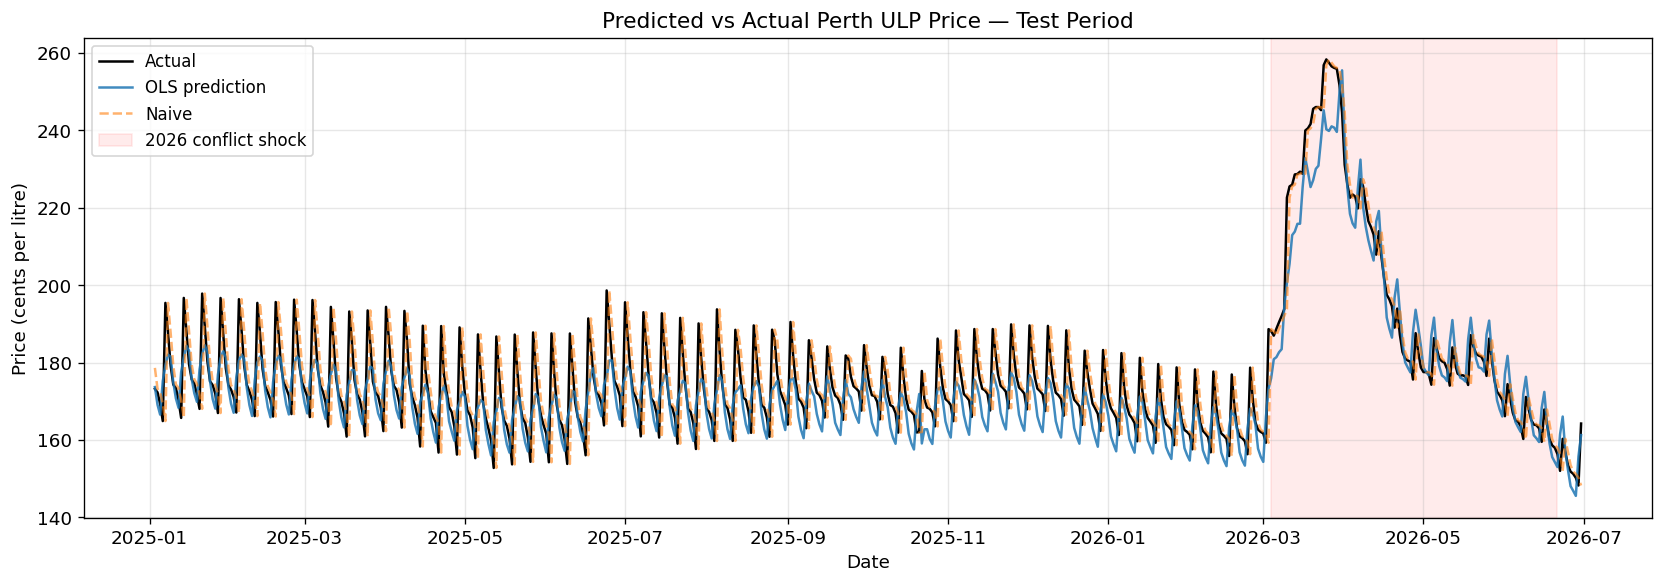

In [16]:
# =========================================================
# Section 12: Graph 1 - Actual vs Predicted over the test period
# Shows the actual price line, the OLS prediction, the naive
# baseline, and shades the 2026 shock regime.
# This is the headline figure of the results section.
# =========================================================
shock_start = pd.Timestamp('2026-03-04')
shock_end   = pd.Timestamp('2026-06-21')

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_eval['date'], test_eval['actual'],
        label='Actual', color='black', linewidth=1.5)
ax.plot(test_eval['date'], test_eval['pred_ols'],
        label='OLS prediction', color='tab:blue', alpha=0.85)
ax.plot(test_eval['date'], test_eval['pred_naive'],
        label='Naive', color='tab:orange', alpha=0.6, linestyle='--')
ax.axvspan(shock_start, shock_end, color='red', alpha=0.08,
           label='2026 conflict shock')

ax.set_title('Predicted vs Actual Perth ULP Price — Test Period', fontsize=13)
ax.set_ylabel('Price (cents per litre)')
ax.set_xlabel('Date')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('fig1_predictions.png', dpi=150)
plt.show()

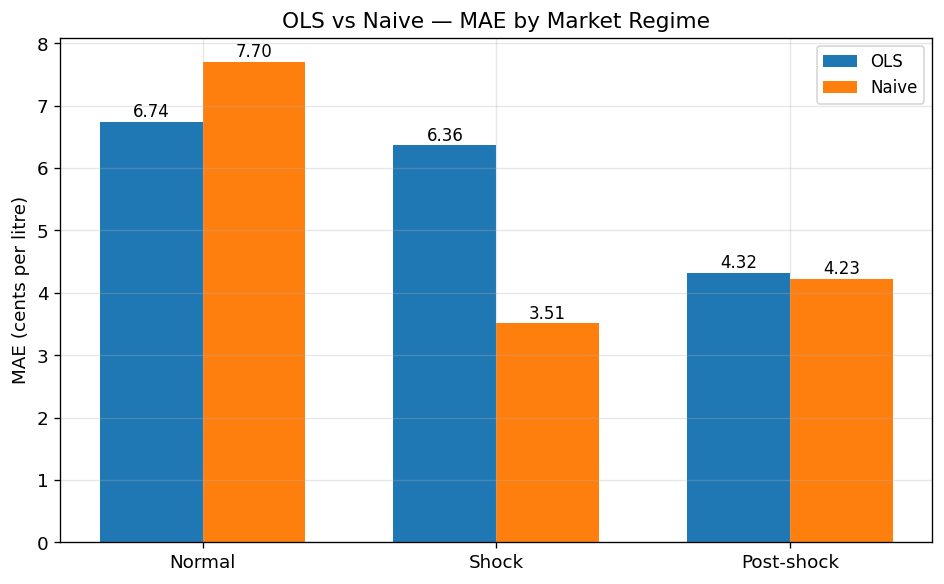

In [17]:
# =========================================================
# Section 13: Graph 2 - MAE by market regime
# Grouped bar chart comparing OLS and naive MAE across the
# three regimes (normal, shock, post-shock).
# This is the key figure showing the OLS breaks down during
# the 2026 conflict shock.
# =========================================================
regimes = ['normal', 'shock', 'post_shock']
labels  = ['Normal', 'Shock', 'Post-shock']

mae_ols   = [mean_absolute_error(
                test_eval.loc[test_eval['regime']==r, 'actual'],
                test_eval.loc[test_eval['regime']==r, 'pred_ols'])
             for r in regimes]
mae_naive = [mean_absolute_error(
                test_eval.loc[test_eval['regime']==r, 'actual'],
                test_eval.loc[test_eval['regime']==r, 'pred_naive'])
             for r in regimes]

x = np.arange(len(labels)); width = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - width/2, mae_ols,   width, label='OLS',   color='tab:blue')
b2 = ax.bar(x + width/2, mae_naive, width, label='Naive', color='tab:orange')

for bars in (b1, b2):
    for bar in bars:
        ax.annotate(f'{bar.get_height():.2f}',
                    xy=(bar.get_x()+bar.get_width()/2, bar.get_height()),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', fontsize=10)

ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel('MAE (cents per litre)')
ax.set_title('OLS vs Naive — MAE by Market Regime', fontsize=13)
ax.legend()
plt.tight_layout()
plt.savefig('fig2_mae_regime.png', dpi=150)
plt.show()

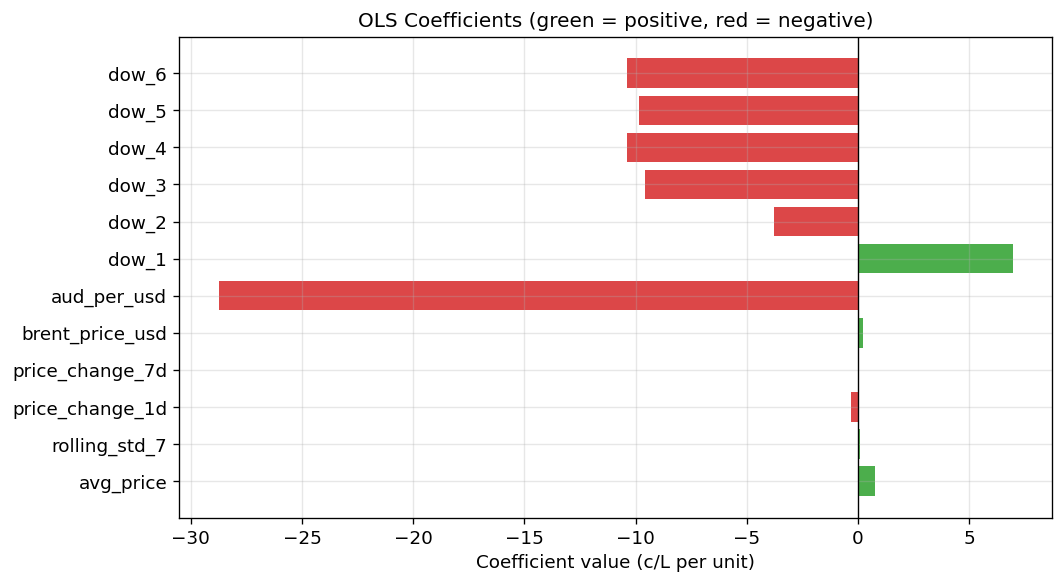

In [18]:
# =========================================================
# Section 14: Graph 3 - OLS coefficients
# Horizontal bar chart of every non-intercept coefficient.
# Green = positive effect on tomorrow's price,
# red = negative effect.
# Visual evidence that the model learned the weekly cycle
# (dow_1 positive, dow_3 through dow_6 negative) and the
# economic drivers (brent positive, aud negative).
# =========================================================
coef = model.params.drop('const')
colors = ['tab:red' if v < 0 else 'tab:green' for v in coef]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(coef.index, coef.values, color=colors, alpha=0.85)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Coefficient value (c/L per unit)')
ax.set_title('OLS Coefficients (green = positive, red = negative)', fontsize=12)
plt.tight_layout()
plt.savefig('fig3_coefficients.png', dpi=150)
plt.show()

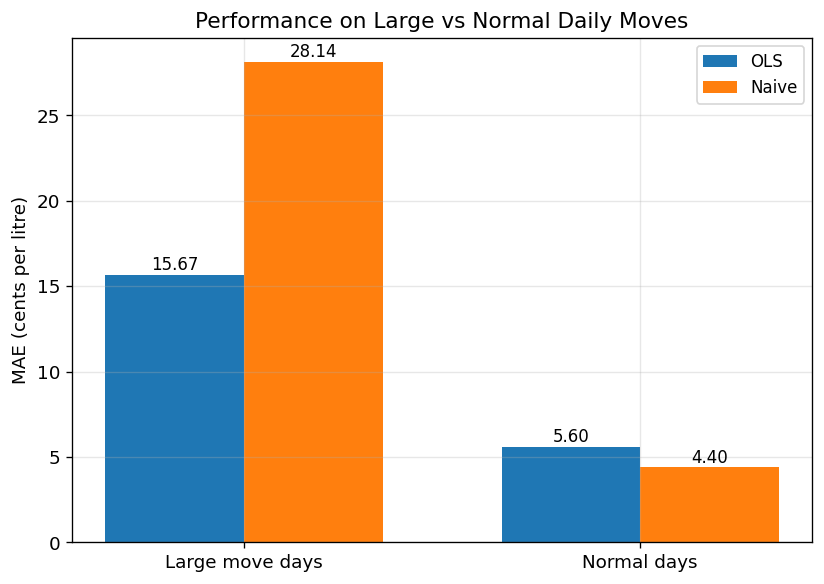

In [19]:
# =========================================================
# Section 15: Graph 4 - Performance on large vs normal moves
# Grouped bar chart comparing OLS and naive MAE on the top
# 10% largest next-day price changes versus all other days.
# Directly answers the proposal objective on large
# day-to-day cycle changes.
# =========================================================
groups = ['Large move days', 'Normal days']

mae_ols_bars = [
    mean_absolute_error(test_eval.loc[test_eval['large_move'], 'actual'],
                        test_eval.loc[test_eval['large_move'], 'pred_ols']),
    mean_absolute_error(test_eval.loc[~test_eval['large_move'], 'actual'],
                        test_eval.loc[~test_eval['large_move'], 'pred_ols']),
]
mae_naive_bars = [
    mean_absolute_error(test_eval.loc[test_eval['large_move'], 'actual'],
                        test_eval.loc[test_eval['large_move'], 'pred_naive']),
    mean_absolute_error(test_eval.loc[~test_eval['large_move'], 'actual'],
                        test_eval.loc[~test_eval['large_move'], 'pred_naive']),
]

x = np.arange(len(groups)); width = 0.35
fig, ax = plt.subplots(figsize=(7, 5))
b1 = ax.bar(x - width/2, mae_ols_bars,   width, label='OLS',   color='tab:blue')
b2 = ax.bar(x + width/2, mae_naive_bars, width, label='Naive', color='tab:orange')

for bars in (b1, b2):
    for bar in bars:
        ax.annotate(f'{bar.get_height():.2f}',
                    xy=(bar.get_x()+bar.get_width()/2, bar.get_height()),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', fontsize=10)

ax.set_xticks(x); ax.set_xticklabels(groups)
ax.set_ylabel('MAE (cents per litre)')
ax.set_title('Performance on Large vs Normal Daily Moves', fontsize=13)
ax.legend()
plt.tight_layout()
plt.savefig('fig4_large_moves.png', dpi=150)
plt.show()